---
---

<h1><center><ins>Numerical Methods: Exam 1</ins></center></h1>
<h2><center>November 11, 09:45-11:15 </center></h2>

Please answer the short questions related to the numerical methods we discussed during the lectures. Provide short and concise (one-two sentences) answers.

Pleasecompute the below questions in the python notebook, *documenting your code* where needed, or create .py files that are documented.

Remember also to **_answer any discussion points asked in the question_**.  

***Before 11:20*** your files need to be uploaded to GitHub.<br>
<br>
This means you have roughly 90 minutes to complete the exercises in this part.

You may use the lecture notes and any of your exercises freely, but you can **not** use ChatGPT code assistant or other AI coding tools such as Claude.<br> 
**_Collaboration or plagarized code except your own is prohibited and no phones or communication will be allowed_**.

---
---

## Short questions
1. Is the symmetrical or non-symmetrical version of the numerical derivative more precise? Why is one of the way of calculating it more precise than the other from the mathematical points of view? (**2 points**)
2. What is the difference between 1/3 and 3/8 Simpson's rules of numerical integration? Which rule usually has higher precision? (**2 points**)
3. Describe in a sentence or two what is the main difference between the Hermite Taylor and the spline interpolations. Does using higher degrees of polinomial interpolation always improves the precision? (**2 points**)
4. What is the difference between an interpolating, approximating, and extrapolating function? (**2 points**)
5. What are the typical methods of solving the systems of non-linear equations? Is a general solution usually possible? (**2 points**)

Answers:
1. The symmetrical method is more accurate, because with the appropriate choice of h, the fractional error is ~ ε 2/3, typically 1 or 2 orders of magnitude better than with the non-symmetrized form. Mathematically, the Taylor expansion of x(t+h) − x(t−h) cancels the even-order terms, including the h² term, so its error is O(h²), while the forward difference keeps the x’’* (h/2) term and has an error of O(h)'

2. The 1/3 rule approximates the integrand using a quadratic polynomial and requires an even number of subintervals (i.e., the interval is divided into an even number of segments). The 3/8 rule, on the other hand, uses a cubic polynomial and requires the interval to be divided into a multiple of three subintervals.

3. Cubic Hermite interpolation produces an approximation, that is differentiable with a continuous derivative; Cubic Hermite interpolation is useful when generating continuous output when solving ordinary differential equations.

4. For interpolation you make a slope that passes through all of the data points and create a polynomial. With approximation not every data points must be "hit" exactly, it can just be close to the data points, extrapolating is when the polynomial goes outside of the data points as well, so it continues to the left and right of the interoolation.

5. Newton-Rahpson, Broyden method, etc. NOT LU decomposition as that is for systems of linear equations. No general solution available. 



In [138]:
import numpy as np
from matplotlib import pyplot as plt
import scipy

## Exercise 1. Calculate the mass of the Sun (10 Points)

Internal structure of stars can be described by a set of equations including the mass continuity equation. The density inside the Sun can be described in a simplified way by the following polynomial:

$$
d(x) = 
519x^4 - 1630x^3 + 1844x^2 - 889x + 155
$$

Here, x is the dimensionless solar radius $x = R/R_\odot$ that goes from 0 at the centre to 1 at the Sun's surface. The density is in g/cm$³$. The solar radius $R_\odot =  6.9 \times 10^{10}$ cm. 

**(a)** Create the integrand that you would use to calculate the Sun's mass using the density profile given above. Hint: don't forget that you need to intergrate  the spherical coordinate system (**1 point**)

**(b)** Numerically integrate the mass continuity equation for the Sun that uses the density profile given above using the Simpson's 1/3 rule (**5 points** is you use your own implementation of the algorithm, **1 point** if you use an embedded function)

(NB: your result will be somewhat different from the precise solar mass of $1.989 \times 10^{33}$ g, this is due to simplifications used in the density profile, but it should not be orders of magnitude different)

**(c)** Find and print the radius at which the density equals 1 g/cm$^3$ (the density of water) **within the interval 0.8 \le x \le 1** (**1 point**)


**(d)** Plot the density profile (**2 points**)




The Sun's mass is 2.8602291922203046e+33 g, which is 2.860229192220304e+30.
The Sun's mass is 1.4380237266064877 solar masses. This deviates a bit from the actual value as expected however the oder of magnitude is the same.
The density equals 1 at the dimensionless radius: The root is 0.8872689664933532 and it took 6 iterations to find it.
The desntiy equals 1 at the radius: 61221558688.04137 cm, which is 612215.5868804137 km.


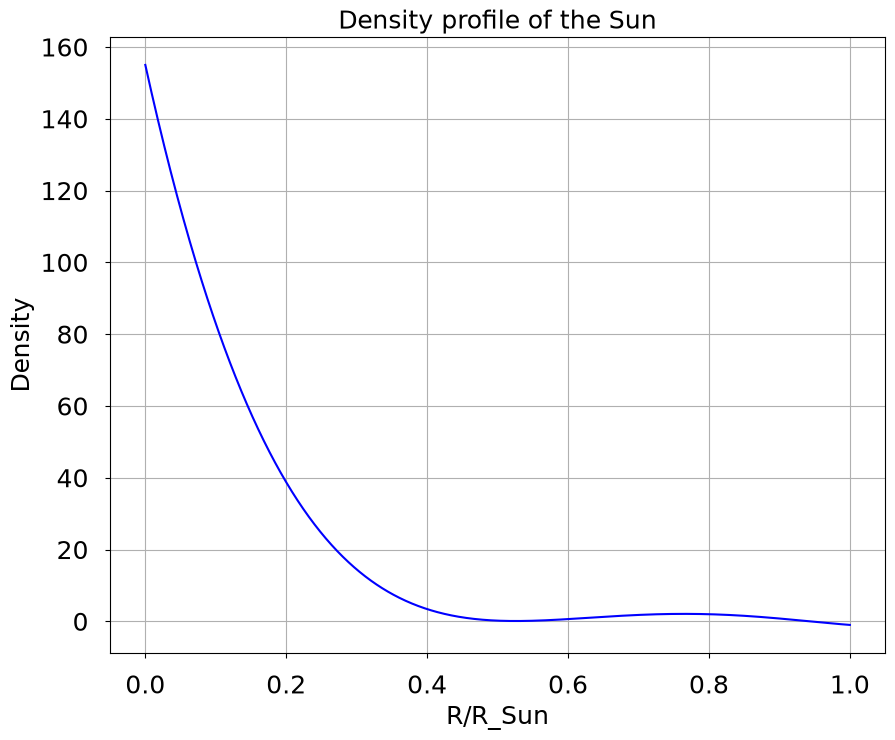

In [139]:
def d(x):
    return 519*x**4 - 1630*x**3 + 1844*x**2 - 889*x +155

# (a)

# M = int int int_V rho(r) dV
# here dV = r^2 sin(theta) dr d theta d phi
# boundaries: dr: [0, R], sin(theta) d theta: [0, pi], d phi: [0, 2 pi]
# M = rho * int_0^R 4 pi r^2 dr (rho is d(x))
# x = R/R_sun -> R = R_sun * x => dr = R_sun dx ! 
 
def integrand(R):
    return d(R) * 4* np.pi * R**2 * (R_sun)**3

#mass, error = scipy.integrate.quad(integrand, 0, 1)
#print(mass)

# (b) 
a = 0
b = 1

M_sun = 1.989 * 10**(33) # g !! 
R_sun = 6.9 * 10**(10) # cm !!!!! 

def simpson_integration(f_vals, x_vals):
 
    n_points = len(x_vals)

    # Check requirements
    if n_points % 2 == 0:
        raise ValueError(f"Simpson's rule requires odd number of points, got {n_points}")

    # Check even spacing
    h = np.diff(x_vals)
    if not np.allclose(h, h[0]):
        raise ValueError("Simpson's rule requires evenly spaced data")
    h = h[0]

    # Compute sum
    integral = f_vals[0] + f_vals[-1]  # Endpoints

    # Odd indices (1, 3, 5, ...) get multiplied by 4
    for i in range(1, n_points - 1, 2):
        integral += 4 * f_vals[i]

    # Even indices (2, 4, 6, ...) get multiplied by 2
    for i in range(2, n_points - 1, 2):
        integral += 2 * f_vals[i]

    integral *= (h / 3.0)
    return integral

def simpson_integration_functional(func, a, b, num_points=1001):

    # Ensure odd number of points
    if num_points % 2 == 0:
        num_points += 1

    x_vals = np.linspace(a, b, num_points)
    f_vals = func(x_vals)
    return simpson_integration(f_vals, x_vals)

print(f"The Sun's mass is {simpson_integration_functional(integrand,a,b)} g, which is {((2.8602291922203046 * 10**(33))/(10**3))}.")
print(f"The Sun's mass is {(2.8602291922203046 * 10**(33))/M_sun} solar masses. This deviates a bit from the actual value as expected however the oder of magnitude is the same.")
#mass, error = scipy.integrate.quad(integrand,0,1)
#print(mass)

# (c)

# d(x) = 1 => d(x) - 1 = 0 -> root!

def new_d(x):
    return d(x) - 1

epsilon = 10**(-6)

# Secant method -> chose this one because it gave me the closest result to the actual value (tried this in a different file)
def secant(func, a, b):
    if func(a)*func(b) >= 0:
        return None
    
    count = 0 

    while True: 
        x_r = b - (func(b)/(func(b)-func(a)))*(b-a)
        count += 1 

        if np.abs(x_r-b) < epsilon:
            return f'The root is {x_r} and it took {count} iterations to find it.'

        a, b = b, x_r
result2 = secant(new_d, a, b)
print(f'The density equals 1 at the dimensionless radius: {result2}')
print(f'The desntiy equals 1 at the radius: {(0.8872689664933532)*R_sun} cm, which is {((0.8872689664933532)*R_sun)/(10**5)} km.')  


# (d) 
# density profile plot 

x_axis = np.linspace(0, 1, 1000)

plt.figure(figsize=(10,8)) 
plt.tick_params(axis ='x', which ='major', 
               labelsize = 18, pad = 12, 
               colors ='black')

plt.tick_params(axis ='y', which ='major', 
               labelsize = 18, pad = 12, 
               colors ='black')

plt.title("Density profile of the Sun", size=18)
plt.xlabel("R/R_Sun", size=18) 
plt.ylabel("Density", size=18)

plt.grid()
plt.plot(x_axis, d(x_axis), c='b')
plt.show()


## Exercise 2. Find the boundary of the Sun's convective zone (10 Points)


In solar-like stars, convection sets in when the magnitude of the temperature gradient exceeds the adiabatic temperature gradient:

$$
\left|\frac{dT}{dx}\right|>\frac{g(x)}{c_p(x)}.
$$

Here, $g(x)$ is the gravitational acceleration, $c_p(x)$ is the specific heat capacity at constant pressure, and $x=r/R_\odot$ is the dimensionless radius. The solar radius is $R_\odot=6.96\times10^8\,\mathrm{m}$. The following simplified model of the Sun is valid for $0.55\leq x\leq0.85$.

The temperature profile is approximated by

$$
T(x)=2.2\times10^6-R_\odot\left[
0.015(x-0.713)
+0.006(x-0.713)^2
+0.010(x-0.713)^3
\right]\ \mathrm{K}.
$$

The adiabatic temperature gradient is approximated by

$$
\frac{g(x)}{c_p(x)}
=0.015[1-0.2(x-0.713)]\ \mathrm{K/m}.
$$

**Hint:** you get an easy expression for the for the radial temperature gradient $dT/dy = -(0.015 + 0.012y + 0.030y^2)$ if you assume $y = x - 0.713$. Just don't forget to subtract 0.713 from the value of $x$ when calculating the derivative.

(**a**) Define the function whose root corresponds to the boundary between the radiative and convective regions (**2 points**)

(**b**) Use a numerical root-finding algorithm (the bisection method) to determine the radius at which the convection begins. Use the interval $0.6\leq x\leq0.8$ and an accuracy of $10^{-5}$ (**5 points** if you use your own function, **1 point** if you use an embedded python function)

(**c**) Print your result from **b** in units of the solar radius and in meters (**1 point**)

(**d**) Plot both temperature gradients ($dT/dx$ and the adiabatic gradient) as functions of \(x\) and indicate the boundary between the radiative and convective regions (**2 points**)

Convection begins at radius 0.6304016113281249 (dimensionless), which is 43497711181.64062 in cm and 434977111.8164062 in m.


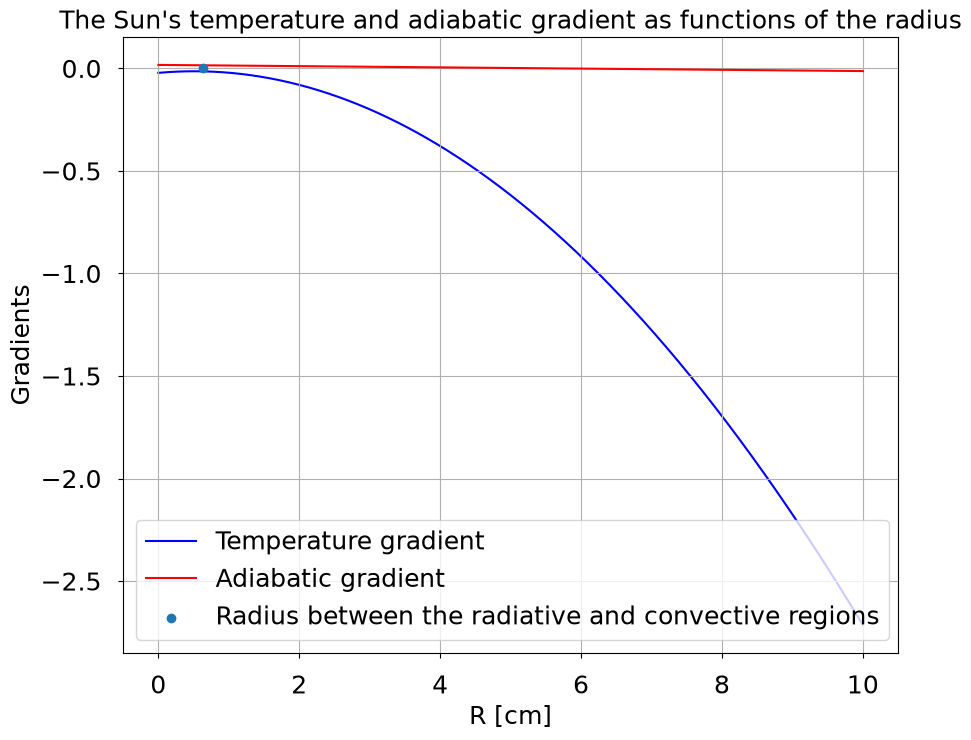

In [140]:
# x => 0.55 and x <= 0.85

def temp_grad(x):
    return -(0.015 + 0.012*(x-0.713) + 0.030*(x-0.713)**2)

def adiabatic_grad(x):
    return 0.015* (1 - 0.2*(x - 0.713))

def new_func(x):
    return np.abs(temp_grad(x)) - adiabatic_grad(x)
    
# print(new_func(1))

R_sun = 6.9 * 10**(10) # cm !!!!! 

epsilon = 10**(-5)
a= 0.6
b= 0.8

def bisection(func,a,b):
    if func(a)*func(b) >= 0:
        return None 
    
    count = 0   

    while True: 
        # while True loop never ends on its own, only when something inside exits (return statement)
        x_m = (a+b)/2 
        count += 1

        # print(a, b, x_m, func(x_m)) 

        if func(x_m) == 0 or (b - a)/2 < epsilon:
            return f'{x_m}'
        
        elif func(x_m)*func(a) < 0:
            # root is in new interval [a, x_m] 
            b = x_m

        elif func(x_m)*func(b) < 0:
            # root is in new interval [x_m, b]
            a = x_m
result1 = bisection(new_d, a, b)

# (c)

print(f'Convection begins at radius {result1} (dimensionless), which is {0.6304016113281249*R_sun} in cm and {(0.6304016113281249*R_sun)/10**2} in m.')  

# (d)

x_axis = np.linspace(0, 10, 1000)

x_x = 0.6304016113281249
y_y = 0 # a bit confused here (:

plt.figure(figsize=(10,8)) 
plt.tick_params(axis ='x', which ='major', 
               labelsize = 18, pad = 12, 
               colors ='black')

plt.tick_params(axis ='y', which ='major', 
               labelsize = 18, pad = 12, 
               colors ='black')

plt.title("The Sun's temperature and adiabatic gradient as functions of the radius", size=18)
plt.xlabel("R [cm]", size=18) 
plt.ylabel("Gradients", size=18)

plt.grid()
plt.plot(x_axis, temp_grad(x_axis), c='b', label="Temperature gradient", zorder=1)
plt.plot(x_axis, adiabatic_grad(x_axis), c='r', label="Adiabatic gradient", zorder=2)
plt.scatter(x_x, y_y, label="Radius between the radiative and convective regions", zorder=3) # i dont know exactly what to plot :,)
plt.legend(prop={'size': 18})
plt.show()


